<a href="https://colab.research.google.com/github/snehag77/Recipe-Generator/blob/main/02_gpt2_finetune.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q keras-hub

import os
os.environ["KERAS_BACKEND"] = "tensorflow"   # before importing keras

import json, re, math
import numpy as np, pandas as pd
import tensorflow as tf, keras, keras_hub
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount("/content/drive")
BASE = "/content/drive/MyDrive/P45_recipe_gen"
MAX_LEN = 256
BATCH = 8            # drop to 4 if you hit out-of-memory errors
SEED = 42
tf.random.set_seed(SEED); np.random.seed(SEED)

def load_jsonl(name):
    with open(f"{BASE}/data/{name}.jsonl") as f:
        return [json.loads(l) for l in f]

train, val, test = load_jsonl("train"), load_jsonl("val"), load_jsonl("test")
train_texts = [r["text"] for r in train]
val_texts   = [r["text"] for r in val]
test_texts  = [r["text"] for r in test]
print(len(train_texts), len(val_texts), len(test_texts))
print("GPU:", tf.config.list_physical_devices("GPU"))

Mounted at /content/drive
27000 1500 1500
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
def build_prompt(ingredient_list):
    ings = [i.strip().lower() for i in ingredient_list if i.strip()]
    return f"<INGREDIENTS> {', '.join(ings)} <END_ING>\n<TITLE>"

REQUIRED = ["<TITLE>", "<END_TITLE>", "<QUANTITIES>", "<END_QTY>", "<STEPS>", "<END_STEPS>"]
def format_adherence(text):
    return sum(t in text for t in REQUIRED) / len(REQUIRED)

def ingredient_coverage(ings, text):
    t = text.lower()
    return sum(i.lower() in t for i in ings) / len(ings)

def trim_output(text):
    """Cut anything the model wrote after <END_STEPS>."""
    i = text.find("<END_STEPS>")
    return text[: i + len("<END_STEPS>")] if i != -1 else text

In [5]:
keras.mixed_precision.set_global_policy("mixed_float16")

preprocessor = keras_hub.models.GPT2CausalLMPreprocessor.from_preset(
    "gpt2_base_en", sequence_length=MAX_LEN)

def make_ds(texts, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices(texts)
    if shuffle:
        ds = ds.shuffle(10_000, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH, drop_remainder=False)
    ds = ds.map(preprocessor, num_parallel_calls=tf.data.AUTOTUNE)   # tokenize + shift labels
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(train_texts, shuffle=True)
val_ds   = make_ds(val_texts)
test_ds  = make_ds(test_texts)

# inspect one batch
x, y, w = next(iter(train_ds))
print({k: v.shape for k, v in x.items()}, y.shape, w.shape)

{'token_ids': TensorShape([8, 256]), 'padding_mask': TensorShape([8, 256])} (8, 256) (8, 256)


In [6]:
gpt2 = keras_hub.models.GPT2CausalLM.from_preset("gpt2_base_en", preprocessor=None)

def compile_model(model, lr_schedule):
    model.compile(
        optimizer=keras.optimizers.AdamW(learning_rate=lr_schedule, weight_decay=0.01),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        weighted_metrics=["accuracy"],
    )

compile_model(gpt2, 5e-5)
base_loss, base_acc = gpt2.evaluate(test_ds, verbose=1)
base_ppl = math.exp(base_loss)
print(f"BASE  loss={base_loss:.4f}  ppl={base_ppl:.2f}  acc={base_acc:.4f}")

with open(f"{BASE}/outputs/base_metrics.json", "w") as f:
    json.dump({"loss": base_loss, "perplexity": base_ppl, "accuracy": float(base_acc)}, f)

188/188 ━━━━━━━━━━━━━━━━━━━━ 35s 118ms/step - accuracy: 0.4914 - loss: 1.7945
BASE  loss=1.7945  ppl=6.02  acc=0.4914


steps/epoch: 3375 | total: 6750 | warmup: 337


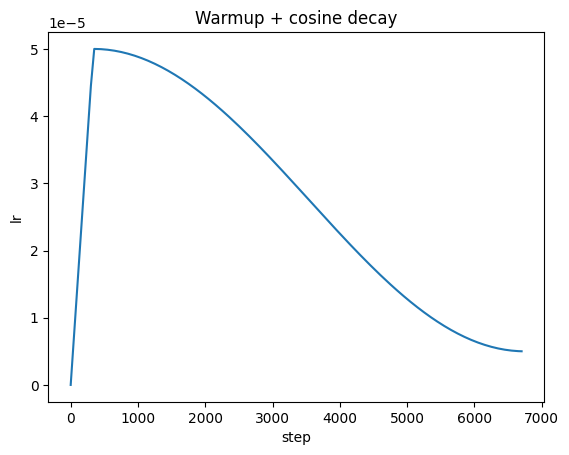

In [7]:
EPOCHS = 2
steps_per_epoch = math.ceil(len(train_texts) / BATCH)
total_steps = steps_per_epoch * EPOCHS
warmup_steps = int(0.05 * total_steps)

lr_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=0.0,
    decay_steps=total_steps - warmup_steps,
    warmup_target=5e-5,
    warmup_steps=warmup_steps,
    alpha=0.1,                      # decays to 10% of peak
)
print("steps/epoch:", steps_per_epoch, "| total:", total_steps, "| warmup:", warmup_steps)

# plot the schedule for your report
lrs = [float(lr_schedule(s)) for s in range(0, total_steps, 50)]
plt.plot(range(0, total_steps, 50), lrs); plt.xlabel("step"); plt.ylabel("lr")
plt.title("Warmup + cosine decay"); plt.show()

In [8]:
compile_model(gpt2, lr_schedule)

CKPT_DIR = f"{BASE}/checkpoints"
callbacks = [
    keras.callbacks.TensorBoard(log_dir=f"{BASE}/logs/gpt2_run1"),
    keras.callbacks.CSVLogger(f"{BASE}/logs/gpt2_history.csv", append=True),
    keras.callbacks.ModelCheckpoint(
        f"{CKPT_DIR}/gpt2_epoch{{epoch:02d}}.weights.h5",
        save_weights_only=True, save_best_only=False),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=1,
                                  restore_best_weights=True),
]

history = gpt2.fit(train_ds, validation_data=val_ds,
                   epochs=EPOCHS, callbacks=callbacks)

Epoch 1/2
3375/3375 ━━━━━━━━━━━━━━━━━━━━ 1156s 312ms/step - accuracy: 0.6845 - loss: 0.9658 - val_accuracy: 0.7155 - val_loss: 0.8393
Epoch 2/2
3375/3375 ━━━━━━━━━━━━━━━━━━━━ 1044s 309ms/step - accuracy: 0.7139 - loss: 0.8356 - val_accuracy: 0.7226 - val_loss: 0.8102


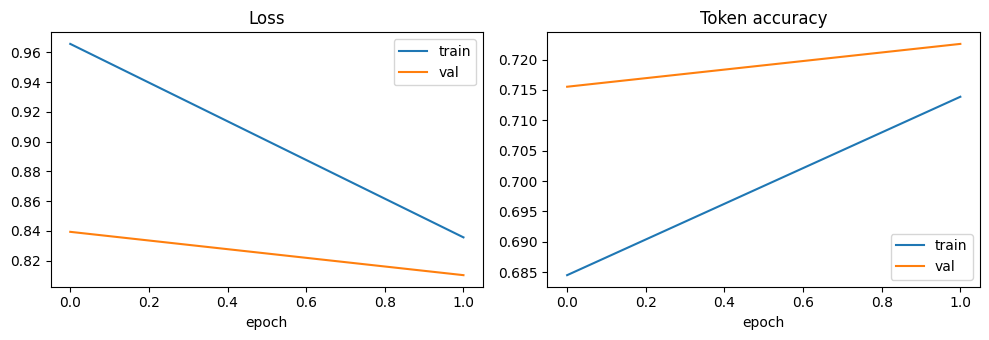

In [9]:
hist = pd.read_csv(f"{BASE}/logs/gpt2_history.csv")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(hist["loss"], label="train"); ax[0].plot(hist["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(hist["accuracy"], label="train"); ax[1].plot(hist["val_accuracy"], label="val")
ax[1].set_title("Token accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout()
plt.savefig(f"{BASE}/outputs/gpt2_curves.png", dpi=150); plt.show()

In [10]:
ft_loss, ft_acc = gpt2.evaluate(test_ds, verbose=1)
ft_ppl = math.exp(ft_loss)
print(f"FINE-TUNED  loss={ft_loss:.4f}  ppl={ft_ppl:.2f}  acc={ft_acc:.4f}")

with open(f"{BASE}/outputs/finetuned_metrics.json", "w") as f:
    json.dump({"loss": ft_loss, "perplexity": ft_ppl, "accuracy": float(ft_acc)}, f)

gpt2.save_weights(f"{CKPT_DIR}/gpt2_finetuned_final.weights.h5")

188/188 ━━━━━━━━━━━━━━━━━━━━ 21s 98ms/step - accuracy: 0.7251 - loss: 0.8040
FINE-TUNED  loss=0.8040  ppl=2.23  acc=0.7251


In [11]:
def make_generator(backbone):
    m = keras_hub.models.GPT2CausalLM(backbone=backbone, preprocessor=preprocessor)
    m.compile(sampler=keras_hub.samplers.TopKSampler(k=40, temperature=0.8, seed=SEED))
    return m

ft_gen = make_generator(gpt2.backbone)

def generate(model, ingredient_sets):
    prompts = [build_prompt(s) for s in ingredient_sets]
    outs = model.generate(prompts, max_length=MAX_LEN)
    return [trim_output(o) for o in outs]

TEST_SETS = json.load(open(f"{BASE}/outputs/test_sets.json"))
ft_texts = generate(ft_gen, TEST_SETS)
for s, t in zip(TEST_SETS, ft_texts):
    print("=" * 70); print("INPUT:", s); print(t)

INPUT: ['chicken', 'rice', 'garlic', 'soy sauce']
<INGREDIENTS> chicken, rice, garlic, soy sauce <END_ING>
<TITLE> Honey Dukes <END_TITLE>
<QUANTITIES> 1 can chicken wings; 1 can rice; 1 can soy sauce; 1/2 c. garlic <END_QTY>
<STEPS> 1. Place in a baking dish to be coated with a little water. 2. Bake at 375° for about 10 to 15 minutes. 3. When brown, remove from oven and let cool slightly. <END_STEPS>
INPUT: ['paneer', 'tomato', 'onion', 'cream', 'garam masala']
<INGREDIENTS> paneer, tomato, onion, cream, garam masala <END_ING>
<TITLE> Barbecue Sauce <END_TITLE>
<QUANTITIES> 1 can cream (not instant); 1/4 c. barbecue sauce; 1 onion, diced; 1 Tbsp. garam masala; 1 pkg. Tabasco dry mustard mix; 2 pkg. Velveeta or black pepper <END_QTY>
<STEPS> 1. Mix all ingredients well. 2. Serve with barbecue sauce. 3. Yields 8 servings. <END_STEPS>
INPUT: ['flour', 'butter', 'sugar', 'eggs', 'vanilla']
<INGREDIENTS> flour, butter, sugar, eggs, vanilla <END_ING>
<TITLE> Flour Cookies <END_TITLE>
<QUANT

In [12]:
base_outputs = json.load(open(f"{BASE}/outputs/base_outputs.json"))
rows = []
for b, ft in zip(base_outputs, ft_texts):
    ings = b["ingredients"]
    base_t = trim_output(b["output"])
    rows.append({
        "ingredients": ", ".join(ings),
        "base_output": base_t,
        "finetuned_output": ft,
        "base_format": format_adherence(base_t),
        "ft_format": format_adherence(ft),
        "base_coverage": ingredient_coverage(ings, base_t),
        "ft_coverage": ingredient_coverage(ings, ft),
    })
cmp_df = pd.DataFrame(rows)
cmp_df.to_json(f"{BASE}/outputs/comparison_5sets.json", orient="records", indent=2)
cmp_df[["ingredients", "base_format", "ft_format", "base_coverage", "ft_coverage"]]

,ingredients,base_format,ft_format,base_coverage,ft_coverage
0,"chicken, rice, garlic, soy sauce",0.333333,1.0,1.0,1.0
1,"paneer, tomato, onion, cream, garam masala",0.166667,1.0,1.0,1.0
2,"flour, butter, sugar, eggs, vanilla",0.166667,1.0,1.0,1.0
3,"potato, spinach, chickpeas, cumin",0.166667,1.0,1.0,1.0
4,"banana, peanut butter, oats, honey",0.166667,1.0,1.0,1.0


In [13]:
for r in rows:
    print("#" * 70); print("INGREDIENTS:", r["ingredients"])
    print("\n[BASE]\n", r["base_output"]); print("\n[FINE-TUNED]\n", r["finetuned_output"])

######################################################################
INGREDIENTS: chicken, rice, garlic, soy sauce

[BASE]
 <INGREDIENTS> chicken, rice, garlic, soy sauce <END_ING>
<TITLE>Mushrooms <END_TITLE>Sugar <END_TITLE>Tofu <END_TITLE>
<END_TITLE>Kimchi (sugar) <END_TITLE>
<END_TITLE>Pasta (pasta) <END_TITLE>
<END_TITLE>Pasta with sugar <END_TITLE>
<END_TITLE>Pasta with soy sauce <END_TITLE>
<END_TITLE>Pasta with soy sauce with no sugar <END_TITLE>
<END_TITLE>Pasta with soy sauce with soy sauce with no sugar <END_TITLE>
<END_TITLE>Pasta with soy sauce with soy sauce with a no sugar <END_TITLE>
<END_TITLE>Pasta with soy sauce with soy sauce with soy sauce with soy sauce with soy sauce with soy sauce with soy sauce <END_TITLE>Pasta with soy sauce with soy sauce with soy sauce with soy sauce with soy sauce <END_TITLE>Pasta

[FINE-TUNED]
 <INGREDIENTS> chicken, rice, garlic, soy sauce <END_ING>
<TITLE> Honey Dukes <END_TITLE>
<QUANTITIES> 1 can chicken wings; 1 can rice; 1 can soy

In [15]:
N_EVAL = 50
eval_sets = [r["NER"][:6] for r in test[:N_EVAL]]

ft_eval = generate(ft_gen, eval_sets)

# fresh base model for the same prompts
base_gen = make_generator(
    keras_hub.models.GPT2CausalLM.from_preset("gpt2_base_en", preprocessor=None).backbone)
base_eval = generate(base_gen, eval_sets)

def summarize(name, texts):
    fa = np.mean([format_adherence(t) for t in texts])
    full = np.mean([format_adherence(t) == 1.0 for t in texts])
    cov = np.mean([ingredient_coverage(s, t) for s, t in zip(eval_sets, texts)])
    return {"model": name, "avg_format": fa, "pct_fully_formatted": full, "avg_coverage": cov}

summary = pd.DataFrame([summarize("base", base_eval), summarize("fine-tuned", ft_eval)])
summary["perplexity"] = [base_ppl, ft_ppl]
summary.to_csv(f"{BASE}/outputs/summary_metrics.csv", index=False)
summary

,model,avg_format,pct_fully_formatted,avg_coverage,perplexity
0,base,0.166667,0.0,1.0,6.016254
1,fine-tuned,1.000000,1.0,1.0,2.234415
